In [2]:
import numpy as np
import os
import matplotlib.pyplot as plt
import spiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from kepler_utils import *
import batman_utils

looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected


In [3]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
period=0.2803                               #orbital period [days]
rp = 0.0204                                 #planet radius [stellar radii / rs]
rs = 0.68                                   #stellar radius [solar radii]
a_AU = 0.007                                #semi-major axis [AU]   
a = AU_to_RS(a_AU, rs)                      #semi-major axis [stellar radii] 
incl = 86.3                                 #orbital inclination [degrees]
ecc = 0.                                    #eccentricity
w = 90.                                     #longitude of periastron [degrees] 
fp = 142e-6                                 #planet-to-star flux ratio / occultation depth Fp/Fs(alpha=0) (integrated day-side flux) - from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
T_eff = 4570                                # stellar effective temperature [K]

u = [0.1, 0.3]                              # Stellar limb darkening coefficients [u1, u2] (placeholders, not from K2-141 data, will be set by theoretical stellar atmosphere models)

Ag = 0.28                                   # Geometric albedo from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
A_B = 3/2*Ag                                # Assuming Lambertian reflectance. PROBABLY UNPHYSICAL!

A = .1                                      # ASSUMPTION (!): Band-integrated albedo of rocky surface (reflected component)

In [4]:
# Define Exoplanet Object
K2_141b = PlanetParams(period=period, incl=incl, ecc=ecc, w=w, r1=rp, r2=1., R=a, T2_eff=T_eff, a_AU=a_AU)

In [5]:
# Wavelength ranges of various instruments in um. These are only effective ranges, used for approximate tophat filters.
effective_lambda_ranges = {
    "MIRI/F1280W": [11.6, 14.0], # MIRI imaging TSO, F1280W. Below CO₂ band, can check CO₂ atmosphere (combined with F1500W)
    "MIRI/F1500W": [13.5, 16.6], # MIRI imaging TSO, F1500W. Used on Trappist (15µm CO₂ band), Long wavelengths for cold nightside
    "MIRI/F1800W": [16.5, 19.5], # MIRI imaging TSO, F1800W. MIRI's thermal background climbs steeply past ~15 µm
    "MIRI/LRS": [5.0, 10.5], # Suggested by Sebastian, LRS runs to ~12 µm but red end trimmed (throughput drops)
    "Spitzer/IRAC2": [4.0, 5.0] # ~Spitzer IRAC channel 2 (4.5 um), to compare with the measured occultation depth fp = 142 ppm (Zieba 2022)
}
for n, r in effective_lambda_ranges.items(): effective_lambda_ranges[n]=1e-6*np.array(r) # convert to meters

# Wavelength ranges of various instruments in um. These are the exact filter ranges to be used with the filter throughput data.
filter_lambda_ranges = {
    "MIRI/F1280W": [11.0654, 14.5816], # MIRI imaging TSO, F1280W. Below CO₂ band, can check CO₂ atmosphere (combined with F1500W)
    "MIRI/F1500W": [12.7875, 17.4925], # MIRI imaging TSO, F1500W. Used on Trappist (15µm CO₂ band), good for cold nightside
    "MIRI/F1800W": [15.5725, 20.8505], # MIRI imaging TSO, F1800W. MIRI's thermal background climbs steeply past ~15 µm
    "Spitzer/IRAC2": [3.6955, 5.1008], # ~Spitzer IRAC channel 2 (4.5 um), to compare with the measured occultation depth fp = 142 ppm (Zieba 2022)
    "MIRI/LRS": [4.8900, 10.6100] # MIRI/LRS 5.0-10.5 um. Filter_paths for 5.0-12.0 um and 5.0-14.0 um are also available.
}
for n, r in filter_lambda_ranges.items(): filter_lambda_ranges[n]=1e-6*np.array(r) # convert to meters

FILTER_DIR = os.path.join(os.path.dirname(os.path.abspath('')), 'Filters', 'Spiderman')
filter_paths = {
    "MIRI/F1280W": os.path.join(FILTER_DIR, "JWST_MIRI.F1280W.spiderman.dat"),
    "MIRI/F1500W": os.path.join(FILTER_DIR, "JWST_MIRI.F1500W.spiderman.dat"),
    "MIRI/F1800W": os.path.join(FILTER_DIR, "JWST_MIRI.F1800W.spiderman.dat"),
    "Spitzer/IRAC2": os.path.join(FILTER_DIR, "Spitzer_IRAC.I2.spiderman.dat"),
    "MIRI/LRS": os.path.join(FILTER_DIR, "MIRI_LRS.5.0-10.5um.spiderman.dat")
}

In [6]:
# Filter to be used
Instrument = "MIRI/F1280W"
lambda_range = filter_lambda_ranges[Instrument] # wavelength range of detector [m]
filter_path = filter_paths[Instrument]

## Full (thermal + reflected) phase curve

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


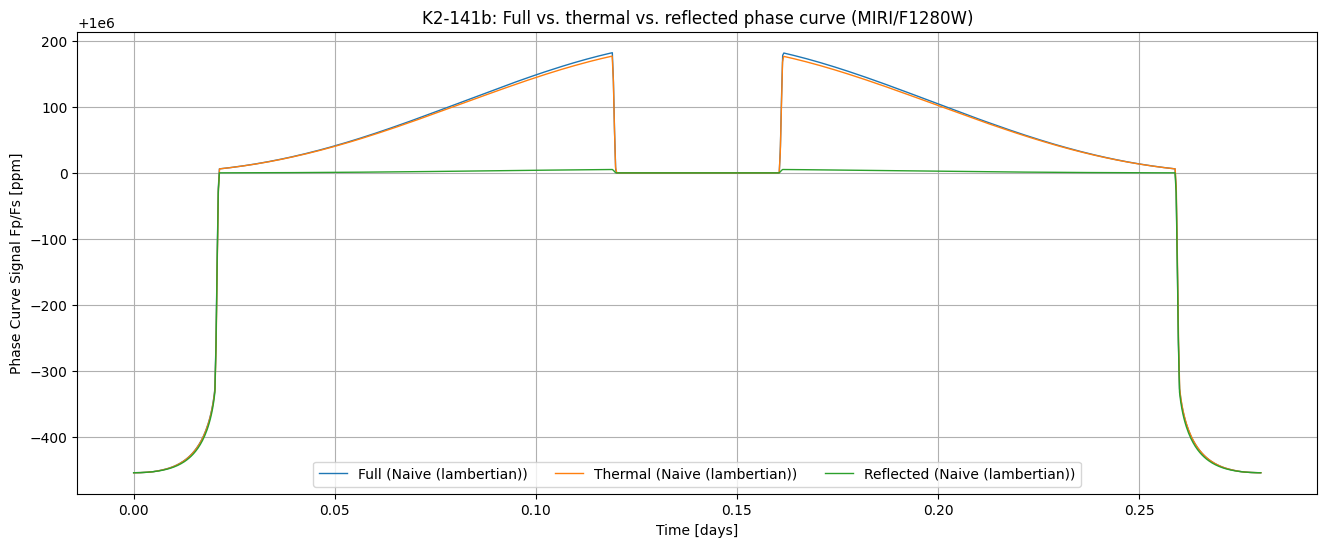

Naive (lambertian)     occultation depth:  full= 197.7  thermal= 192.1  reflected=   5.7  ppm
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


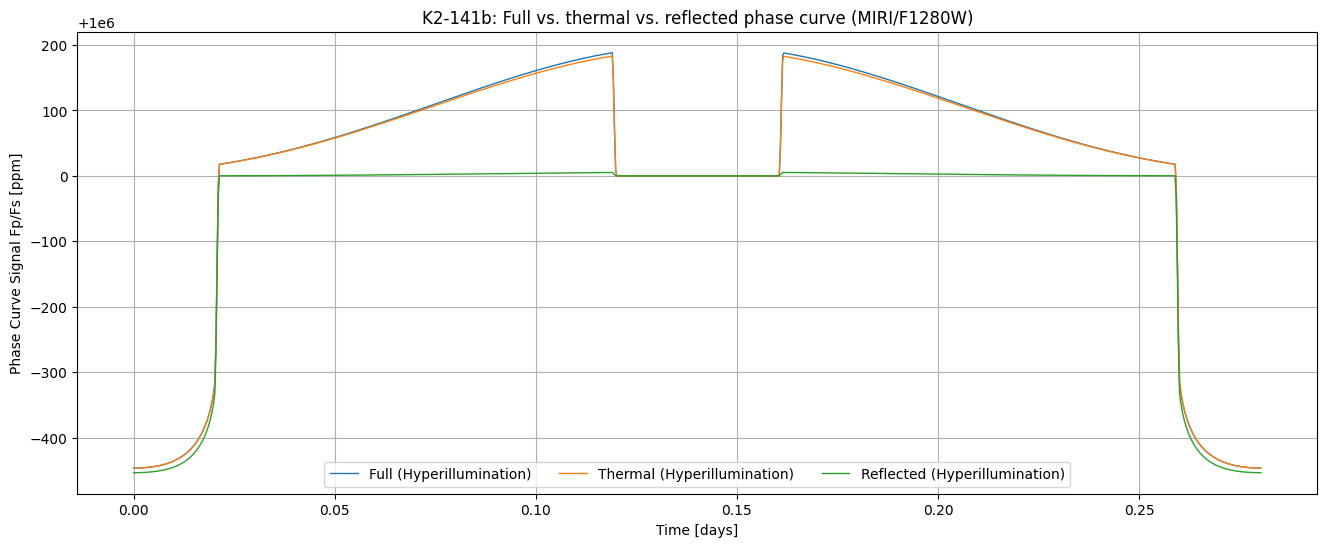

Hyperillumination      occultation depth:  full= 198.8  thermal= 193.1  reflected=   5.7  ppm


In [9]:
for model, mlabel in [("naive", "Naive (lambertian)"), ("kopal", "Hyperillumination")]:
    t_full,  full_pc,  fp_full     = full_PhaseCurve(K2_141b, lambda_range, u=u, A=A, A_B=A_B, filter_path=filter_path, insolation_model=model)
    t_therm, therm_pc, fp_therm, _ = thermal_PhaseCurve(K2_141b, lambda_range, u=u, A_B=A_B, filter_path=filter_path, insolation_model=model)
    t_refl,  refl_pc,  fp_refl     = reflected_PhaseCurve(K2_141b, u=u, A=A, insolation_model=model)
    
    plt.figure(figsize=(16, 6))
    plt.plot(t_full,  full_pc*1e6, color="C0", linewidth=1, label=f"Full ({mlabel})")
    plt.plot(t_therm, therm_pc*1e6, color="C1", linewidth=1, label=f"Thermal ({mlabel})")
    plt.plot(t_refl,  refl_pc*1e6, color="C2", linewidth=1, label=f"Reflected ({mlabel})")
    plt.xlabel("Time [days]")
    plt.ylabel(r"Phase Curve Signal Fp/Fs [ppm]")
    plt.title(f"K2-141b: Full / thermal / reflected phase curve ({Instrument})")
    plt.legend(ncol=3)
    plt.grid()
    plt.show()
    print(f"{mlabel:22s} occultation depth:  full={fp_full:6.1f}  thermal={fp_therm:6.1f}  reflected={fp_refl:6.1f}  ppm")


no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


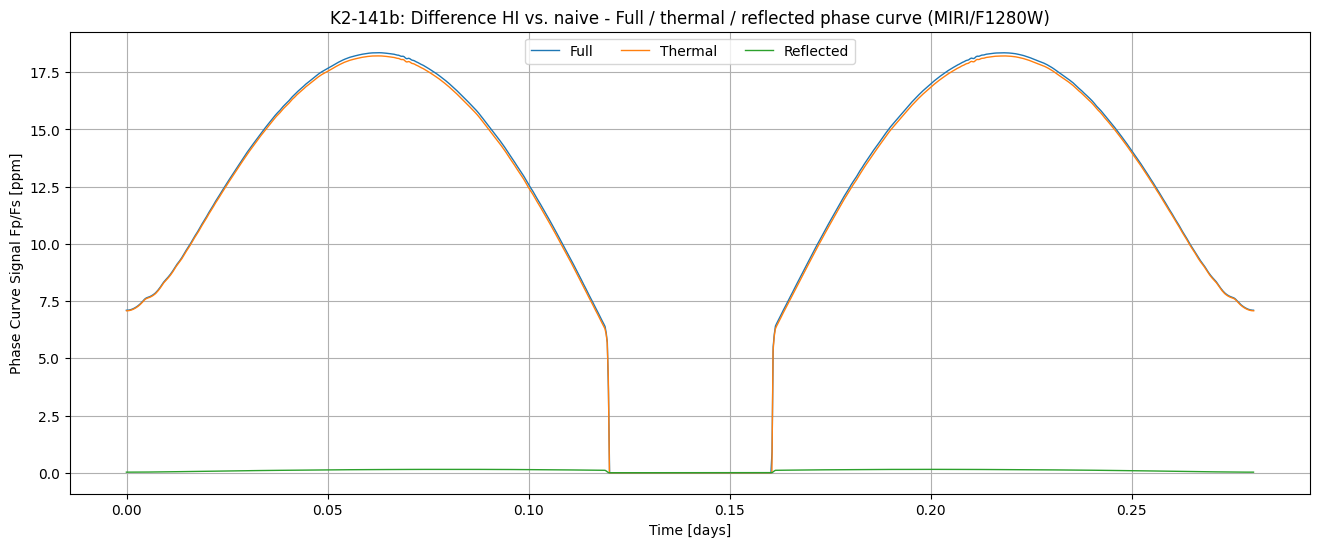

In [12]:
t_full1,  full_pc1,  fp_full1     = full_PhaseCurve(K2_141b, lambda_range, u=u, A=A, A_B=A_B, filter_path=filter_path, insolation_model="naive")
t_therm1, therm_pc1, fp_therm1, _ = thermal_PhaseCurve(K2_141b, lambda_range, u=u, A_B=A_B, filter_path=filter_path, insolation_model="naive")
t_refl1,  refl_pc1,  fp_refl1     = reflected_PhaseCurve(K2_141b, u=u, A=A, insolation_model="naive")
t_full2,  full_pc2,  fp_full2     = full_PhaseCurve(K2_141b, lambda_range, u=u, A=A, A_B=A_B, filter_path=filter_path, insolation_model="kopal")
t_therm2, therm_pc2, fp_therm2, _ = thermal_PhaseCurve(K2_141b, lambda_range, u=u, A_B=A_B, filter_path=filter_path, insolation_model="kopal")
t_refl2,  refl_pc2,  fp_refl2     = reflected_PhaseCurve(K2_141b, u=u, A=A, insolation_model="kopal")

plt.figure(figsize=(16, 6))
plt.plot(t_full1,  np.abs(full_pc1 - full_pc2)*1e6, color="C0", linewidth=1, label=f"Full")
plt.plot(t_therm1, np.abs(therm_pc1 - therm_pc2)*1e6, color="C1", linewidth=1, label=f"Thermal")
plt.plot(t_refl1,  np.abs(refl_pc1 - refl_pc2)*1e6, color="C2", linewidth=1, label=f"Reflected")
plt.xlabel("Time [days]")
plt.ylabel(r"Phase Curve Signal Fp/Fs [ppm]")
plt.title(f"K2-141b: Difference HI vs. naive - Full / thermal / reflected phase curve ({Instrument})")
plt.legend(ncol=3)
plt.grid()
plt.show()